# OL post-snap movement classes: rules + unsupervised clustering

This section can be pasted at the end of the EDA notebook. The setup cell reuses `pp`, `games`, `find_csv`, `pick` and `NULLS` if they already exist, and rebuilds them if not, so it also runs on its own.

**Unit of analysis:** one *rep* = one offensive lineman on one play, lined up at C/G/T, from the snap to `WINDOW_S` seconds later.

**Coordinate frame:** each rep is standardized so the offense moves up the page:
- `depth` = downfield displacement from his snap position (yards; negative = retreating, i.e. a pass set)
- `lat` = lateral displacement from his snap position (yards)

**Left/right caveat:** there's no ball or QB tracking, so we can't directly tell whether a tackle is a LT or RT, or which way is "outside." If `lined_up_position` carries a side (LT/RT/LG/RG), `lat` is signed so that **+ = outside (away from the center)**. Otherwise each rep is mirrored so his main lateral move is **+**. That makes the classes side-agnostic, but it means e.g. a down block and a reach block can't be told apart.

**Two labelings, then compared:**
1. **Rules**: 10 named football classes from thresholds on depth, lateral movement and timing (all in `RULES` below, so they're easy to tune).
2. **Clustering**: k-means (k = 10) on the resampled depth/lateral trajectory and a few speed features, with no labels used.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

sns.set_theme(style="whitegrid", context="notebook")

# ---- data location (always redefined, so an earlier cell can't override it) ----
CANDIDATES = [
    Path("data"),                                   # Ben_EDA/data
    Path("../data"),                                # repo root: USC-NFL-Big-Data-Bowl-2027/data
    Path("data/raw"),
    Path("/kaggle/input/nfl-big-data-bowl-2027"),
]
DATA_DIR = next((p for p in CANDIDATES if (p / "games.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("games.csv not found in: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
print("Data dir:", DATA_DIR.resolve())

NULLS = ["NA", "NULL", "null", "None", ""]

def find_csv(stem):
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists():
        raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return f

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

# ---- load (reuses tables if an earlier cell already loaded them) ----
if "games" not in globals(): games = pd.read_csv(find_csv("games"), na_values=NULLS)
if "pp" not in globals():    pp = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)
if "season" not in pp:       pp = pp.merge(games[["game_id", "season"]], on="game_id", how="left")

# ---- knobs ---------------------------------------------------------------
SEASONS   = [2023, 2024, 2025]
WINDOW_S  = 2.5     # seconds after the snap to analyze
STEP_S    = 0.1     # resampling grid (10 Hz)
MIN_LEN_S = 1.0     # drop reps with less tracked time than this after the snap
K         = 10
RANDOM    = 27
CACHE     = Path("ol_tracking_cache.parquet")
SNAP_EVENTS = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
# --------------------------------------------------------------------------
GRID = np.round(np.arange(0, WINDOW_S + 1e-9, STEP_S), 2)

Data dir: C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


## 1. Pick the OL reps and play context

Only rows where the player actually lined up at C, G or T on that play are used. A guard used as an extra TE in a jumbo package is excluded. Pass vs. run comes from whichever play-type column exists, and the cell prints which one it used.

In [2]:
LUP  = pick(pp, ["lined_up_position", "position_at_snap"], required=True)
DIR  = pick(pp, ["play_direction"])
PASS_COLS = [c for c in [pick(pp, ["is_dropback"]), pick(pp, ["play_type", "pff_run_pass", "pass_run"]),
                         pick(pp, ["pass_result"]), pick(pp, ["dropback_type"])] if c]
print("lined-up col:", LUP, "| direction col:", DIR, "| pass/run cols found:", PASS_COLS)

def ol_spot(p):
    p = str(p).upper().strip()
    if p in {"C", "OC"}: return "C"
    if p in {"G", "OG", "LG", "RG"}: return "G"
    if p in {"T", "OT", "LT", "RT"}: return "T"
    return None

reps = pp.copy()
reps["spot"] = reps[LUP].map(ol_spot)
reps = reps[reps["spot"].notna()].copy()
up = reps[LUP].astype(str).str.upper()
reps["side"] = np.select([up.str.startswith("L"), up.str.startswith("R")], ["L", "R"], default=None)
HAS_SIDE = reps["side"].notna().mean() > 0.5
print(f"OL reps in player_play: {len(reps):,} | players: {reps['nfl_id'].nunique()} | side known: {HAS_SIDE}")

def infer_pass(df):
    s = pd.Series(np.nan, index=df.index, dtype="float")
    for c in PASS_COLS:
        v = df[c]
        if c.lower() == "is_dropback":
            s = s.fillna(v.astype(str).str.lower().isin(["true", "1"]).astype(float).where(v.notna()))
        elif c.lower() in {"pass_result", "dropback_type"}:
            s = s.fillna(v.notna().astype(float).where(v.notna() | s.isna()))
        else:
            lv = v.astype(str).str.lower()
            s = s.fillna(np.select([lv.str.contains("pass"), lv.str.contains("run|rush")], [1.0, 0.0], np.nan))
    return s

reps["is_pass"] = infer_pass(reps)
print("pass/run split:", reps["is_pass"].map({1.0: "pass", 0.0: "run"}).fillna("unknown").value_counts().to_dict())

lined-up col: lined_up_position | direction col: play_direction | pass/run cols found: ['pass_result']
OL reps in player_play: 106,317 | players: 122 | side known: False
pass/run split: {'pass': 64114, 'run': 42203}


## 2. Load OL tracking (chunked and cached)

The first run scans each season file once, keeps only OL rows, and saves a parquet cache. Later runs load from the cache in seconds.

In [3]:
KEEP = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "a", "o", "dir", "event"]
if CACHE.exists():
    trk = pd.read_parquet(CACHE)
else:
    ids = set(reps["nfl_id"]); keys = set(zip(reps["game_id"], reps["play_id"]))
    parts = []
    for season in SEASONS:
        f = find_csv(f"game_tracking_{season}")
        cols = [c for c in KEEP if c in pd.read_csv(f, nrows=1).columns]
        for ch in pd.read_csv(f, usecols=cols, chunksize=2_000_000, na_values=NULLS):
            ch = ch[ch["nfl_id"].isin(ids)]
            parts.append(ch)
        print(season, "done")
    trk = pd.concat(parts, ignore_index=True)
    # keep only (player, play) combos where he lined up on the OL
    trk = trk.merge(reps[["game_id", "play_id", "nfl_id"]], on=["game_id", "play_id", "nfl_id"])
    trk.to_parquet(CACHE, index=False)
print(f"OL tracking rows: {len(trk):,}")

2023 done
2024 done
2025 done
OL tracking rows: 7,547,463


## 3. Build standardized trajectories

For each rep:
1. Find the snap frame, and drop the rep if there is none.
2. Time from snap = `t`. Keep 0 ≤ t ≤ `WINDOW_S`.
3. Rotate so downfield is +depth, then make each coordinate relative to his snap position.
4. Interpolate onto a fixed 0.1 s grid. If tracking ends early (a short play), hold the last position.
5. Set lateral sign: + = outside if the side is known, otherwise mirror so the main lateral move is +.

In [4]:
trk["time"] = pd.to_datetime(trk["time"], errors="coerce")
trk = trk.sort_values(["game_id", "play_id", "nfl_id", "time"])
ctx = reps.set_index(["game_id", "play_id", "nfl_id"])[["spot", "side", "is_pass"] + ([DIR] if DIR else [])]

def standardize(g):
    snap = g.index[g["event"].isin(SNAP_EVENTS)] if "event" in g else []
    if len(snap) == 0: return None
    t = (g["time"] - g.loc[snap[0], "time"]).dt.total_seconds().to_numpy()
    m = (t >= -0.05) & (t <= WINDOW_S + 0.05)
    if m.sum() < 3 or t[m].max() < MIN_LEN_S: return None
    t, x, y, s = t[m], g["x"].to_numpy()[m], g["y"].to_numpy()[m], g["s"].to_numpy()[m]
    return t, x, y, s

rows, mats = [], []
for (gid, pid, nid), g in trk.groupby(["game_id", "play_id", "nfl_id"], sort=False):
    out = standardize(g.reset_index(drop=True))
    if out is None: continue
    t, x, y, s = out
    c = ctx.loc[(gid, pid, nid)] if (gid, pid, nid) in ctx.index else None
    if c is None: continue
    # direction: from player_play if present, else from mean pre-snap orientation (OL face downfield)
    d = c[DIR] if DIR and pd.notna(c[DIR]) else ("right" if np.cos(np.deg2rad(g["o"].iloc[0] - 90)) > 0 else "left")
    sgn = 1 if d == "right" else -1
    depth = sgn * (x - x[0])
    lat_raw = sgn * (y - y[0])                 # + = offense's left when moving right/up
    D = np.interp(GRID, t, depth, right=depth[-1])
    L = np.interp(GRID, t, lat_raw, right=lat_raw[-1])
    S = np.interp(GRID, t, s, right=s[-1])
    if HAS_SIDE and c["side"] in ("L", "R"):
        L = L if c["side"] == "L" else -L      # + = outside
    else:
        L = L if L[np.argmax(np.abs(L))] >= 0 else -L
    rows.append({"game_id": gid, "play_id": pid, "nfl_id": nid, "spot": c["spot"],
                 "is_pass": c["is_pass"], "tracked_s": float(t.max())})
    mats.append(np.r_[D, L, S])

meta = pd.DataFrame(rows)
n = len(GRID)
M = np.vstack(mats)
DEP, LAT, SPD = M[:, :n], M[:, n:2 * n], M[:, 2 * n:]
print(f"Standardized reps: {len(meta):,} | grid points: {n} | by spot:", meta["spot"].value_counts().to_dict())

Standardized reps: 106,267 | grid points: 26 | by spot: {'G': 48491, 'T': 42824, 'C': 14952}


## 4. Summary features per rep

These feed both the rules and the clustering, and they're readable on their own.

In [5]:
def at(arr, sec): return arr[:, int(round(sec / STEP_S))]
absL = np.abs(LAT)
first_move_idx = np.argmax(np.hypot(DEP, LAT) >= 0.5, axis=1).astype(float)
first_move_idx[np.hypot(DEP, LAT).max(axis=1) < 0.5] = np.nan

feat = meta.copy()
feat = feat.assign(
    depth_05=at(DEP, 0.5), depth_10=at(DEP, 1.0), depth_15=at(DEP, 1.5), depth_end=DEP[:, -1],
    lat_05=at(LAT, 0.5), lat_10=at(LAT, 1.0), lat_15=at(LAT, 1.5), lat_end=LAT[:, -1],
    min_depth=DEP.min(axis=1), max_depth=DEP.max(axis=1), max_abs_lat=absL.max(axis=1),
    depth_at_max_lat=DEP[np.arange(len(DEP)), absL.argmax(axis=1)],
    t_min_depth=GRID[DEP.argmin(axis=1)], t_max_depth=GRID[DEP.argmax(axis=1)],
    first_move_s=first_move_idx * STEP_S,
    peak_speed=SPD.max(axis=1), mean_speed=SPD.mean(axis=1),
    path_len=np.hypot(np.diff(DEP, axis=1), np.diff(LAT, axis=1)).sum(axis=1),
)
# set angle at 1.0s: 0° = straight back, 90° = straight lateral, >90° = moving forward
feat["set_angle_10"] = np.degrees(np.arctan2(np.abs(feat["lat_10"]), -feat["depth_10"]))
feat[["depth_10", "lat_10", "min_depth", "max_depth", "max_abs_lat", "peak_speed", "set_angle_10"]].describe().round(2)

,depth_10,lat_10,min_depth,max_depth,max_abs_lat,peak_speed,set_angle_10
count,106267.00,106267.00,106267.00,106267.00,106267.00,106267.00,106267.00
mean,-0.36,0.83,-2.31,0.74,2.54,2.75,70.38
std,0.91,0.75,2.21,1.23,2.23,0.97,47.16
min,-3.70,-1.65,-9.54,0.00,0.01,0.00,0.00
25%,-1.08,0.33,-4.15,0.00,0.93,2.09,26.35
50%,-0.38,0.75,-2.05,0.00,1.64,2.68,68.61
75%,0.35,1.31,-0.00,1.13,3.53,3.34,107.80
max,4.86,5.03,-0.00,11.95,12.70,11.56,180.00


## 5. Rule-based classes

Rules are applied **in priority order** within pass and run plays. The first one that matches wins, and reps matching none are tagged `unclassified`. The unclassified rate is reported as a quality metric. Every threshold lives in `RULES`.

| # | class | play | rule (depth − = backward, lat + = outside or main side) |
|---|---|---|---|
| 1 | `screen_release` | pass | gets ≥ `screen_depth` downfield, after any initial set |
| 2 | `jump_set` | pass | never retreats more than `jump_max_retreat` in first 1.0s and attacks forward ≥ `jump_min_fwd` |
| 3 | `slide` | pass | lateral at 1.0s ≥ `slide_lat` **and** lateral > retreat |
| 4 | `vertical_set` | pass | retreat at 1.0s ≥ `vert_depth`, set angle < `vert_angle`° (mostly straight back) |
| 5 | `45_set` | pass | retreat at 1.0s ≥ `set45_depth`, angle between `vert_angle`° and `set45_angle`° |
| 6 | `quick_set` | pass | shallow retreat: min depth between −`quick_max_retreat` and −0.25 |
| 7 | `pull` | run | lateral ≥ `pull_lat` while staying at/behind the LOS (depth at max lateral ≤ `pull_max_depth`) |
| 8 | `climb` | run | reaches ≥ `climb_depth` downfield (second level) |
| 9 | `zone_reach` | run | lateral at 1.0s ≥ `reach_lat`, not retreating (depth at 1.0s ≥ `reach_min_depth`) |
| 10 | `drive` | run | forward ≥ `drive_fwd` with lateral at 1.0s < `reach_lat` |

If the pass/run flag is missing, rules from both families are tried in this order: screen, pull, climb, then the pass sets, then the run blocks.

In [6]:
RULES = dict(
    screen_depth=3.0,
    jump_max_retreat=0.5, jump_min_fwd=0.5,
    slide_lat=1.5,
    vert_depth=1.75, vert_angle=30,
    set45_depth=1.0, set45_angle=65,
    quick_max_retreat=1.25,
    pull_lat=3.5, pull_max_depth=0.75,
    climb_depth=4.0,
    reach_lat=1.0, reach_min_depth=-0.5,
    drive_fwd=0.5,
)

def classify(f, R=RULES):
    early_min = np.minimum(f["depth_05"], f["depth_10"])
    retreat10 = -f["depth_10"]
    pass_rules = [
        ("screen_release", f["max_depth"] >= R["screen_depth"]),
        ("jump_set",       (early_min >= -R["jump_max_retreat"]) & (f["max_depth"] >= R["jump_min_fwd"])),
        ("slide",          (f["lat_10"].abs() >= R["slide_lat"]) & (f["lat_10"].abs() > retreat10)),
        ("vertical_set",   (retreat10 >= R["vert_depth"]) & (f["set_angle_10"] < R["vert_angle"])),
        ("45_set",         (retreat10 >= R["set45_depth"]) & f["set_angle_10"].between(R["vert_angle"], R["set45_angle"])),
        ("quick_set",      f["min_depth"].between(-R["quick_max_retreat"], -0.25)),
    ]
    run_rules = [
        ("pull",       (f["max_abs_lat"] >= R["pull_lat"]) & (f["depth_at_max_lat"] <= R["pull_max_depth"])),
        ("climb",      f["max_depth"] >= R["climb_depth"]),
        ("zone_reach", (f["lat_10"].abs() >= R["reach_lat"]) & (f["depth_10"] >= R["reach_min_depth"])),
        ("drive",      (f["max_depth"] >= R["drive_fwd"]) & (f["lat_10"].abs() < R["reach_lat"])),
    ]
    lab = pd.Series("unclassified", index=f.index)
    def apply(rules, mask):
        done = pd.Series(False, index=f.index)
        for name, cond in rules:
            hit = mask & ~done & cond
            lab[hit] = name; done |= hit
    apply(pass_rules, f["is_pass"] == 1)
    apply(run_rules,  f["is_pass"] == 0)
    unk = f["is_pass"].isna()
    apply([pass_rules[0], run_rules[0], run_rules[1]] + pass_rules[1:] + run_rules[2:], unk)
    return lab

CLASS_ORDER = ["vertical_set", "45_set", "jump_set", "quick_set", "slide", "screen_release",
               "drive", "zone_reach", "pull", "climb", "unclassified"]
feat["rule_class"] = classify(feat)
summ = (feat.groupby("rule_class").size().reindex(CLASS_ORDER).fillna(0).astype(int).to_frame("reps"))
summ["share"] = (summ["reps"] / summ["reps"].sum()).round(3)
print(f"Unclassified rate: {(feat['rule_class'] == 'unclassified').mean():.1%}")
display(summ)
display(pd.crosstab(feat["rule_class"], feat["spot"], normalize="columns").reindex(CLASS_ORDER).round(3)
          .rename(columns=lambda c: f"share of {c} reps"))

Unclassified rate: 43.1%


,reps,share
rule_class,,
vertical_set,5290,0.050
45_set,6800,0.064
jump_set,3352,0.032
quick_set,2268,0.021
slide,5119,0.048
screen_release,668,0.006
drive,12014,0.113
zone_reach,15501,0.146
pull,6470,0.061


spot,share of C reps,share of G reps,share of T reps
rule_class,,,
vertical_set,0.017,0.004,0.112
45_set,0.091,0.051,0.069
jump_set,0.027,0.034,0.031
quick_set,0.022,0.024,0.018
slide,0.055,0.047,0.047
screen_release,0.005,0.007,0.006
drive,0.115,0.130,0.093
zone_reach,0.136,0.141,0.155
pull,0.060,0.064,0.057


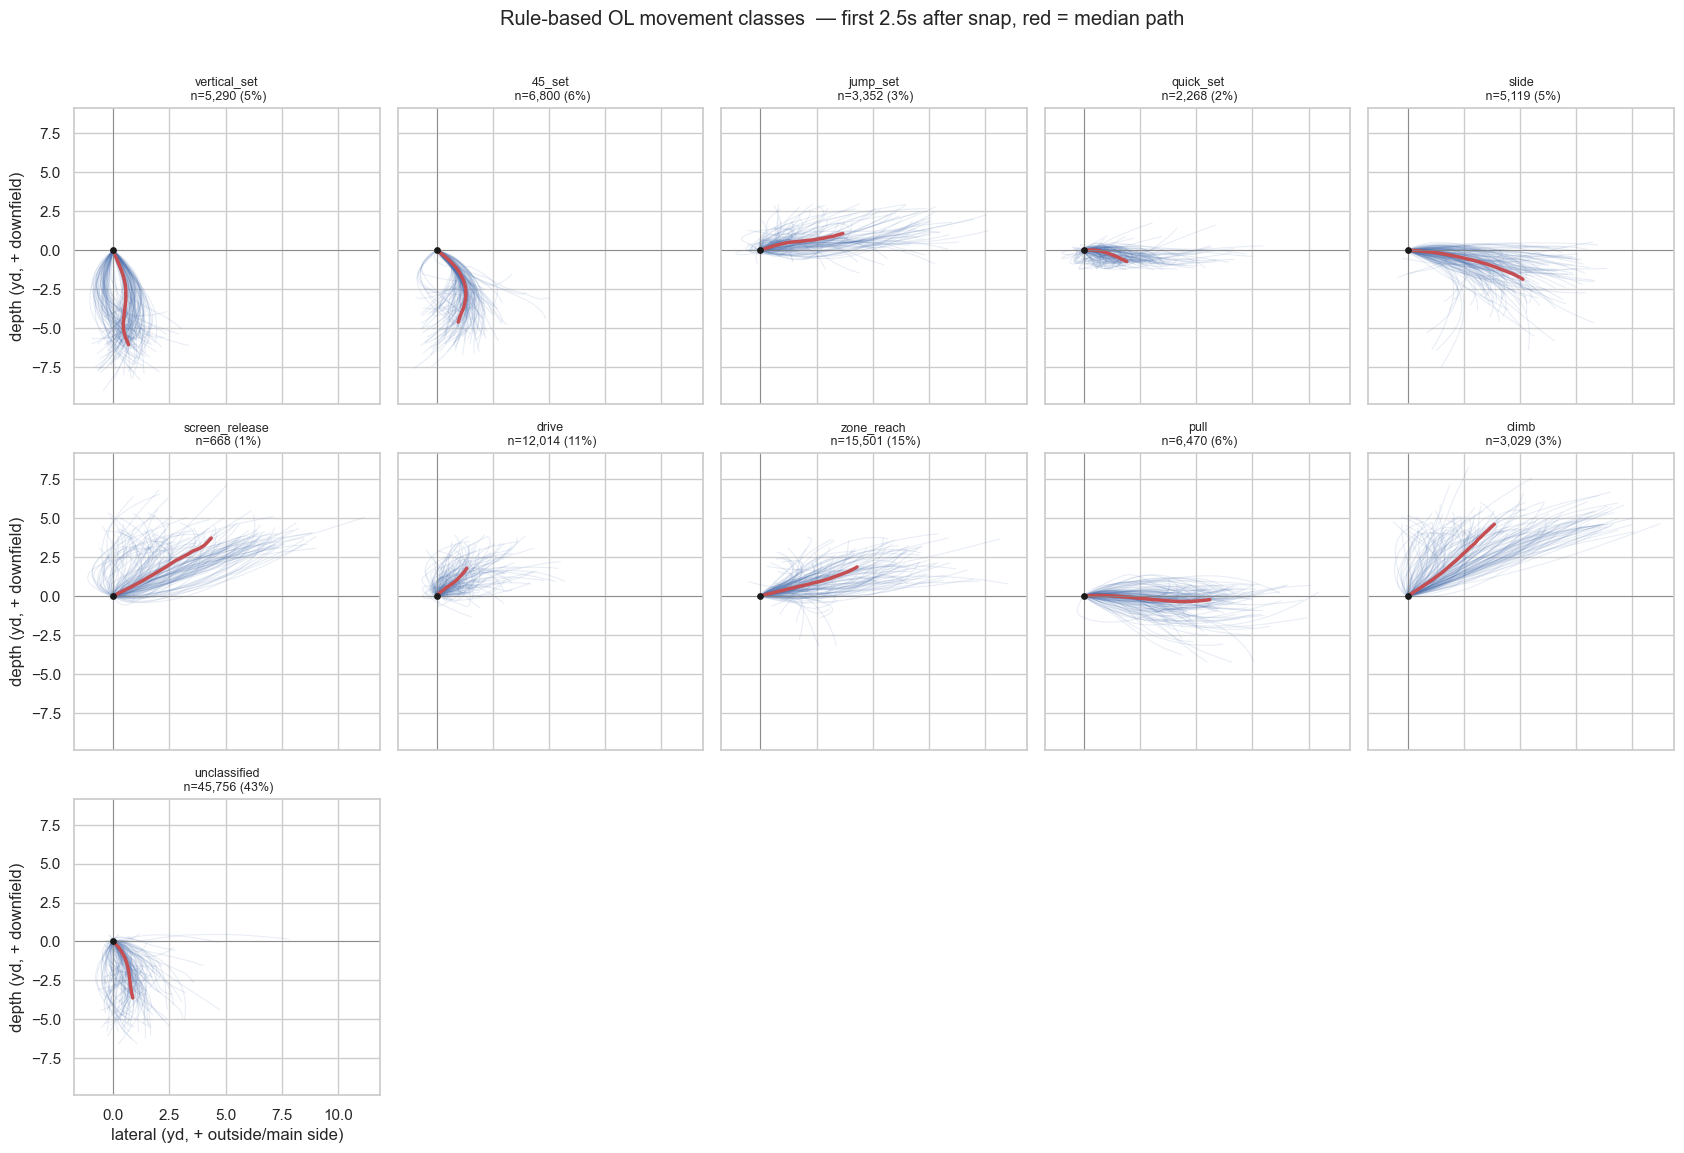

In [7]:
def spaghetti(labels, order, title, n_per=150, ncols=5):
    order = [o for o in order if (labels == o).any()]
    rows = int(np.ceil(len(order) / ncols))
    fig, axes = plt.subplots(rows, ncols, figsize=(3.4 * ncols, 3.8 * rows), squeeze=False, sharex=True, sharey=True)
    rng = np.random.default_rng(RANDOM)
    for ax, lab in zip(axes.flat, order):
        idx = np.flatnonzero(labels == lab)
        for i in rng.choice(idx, min(n_per, len(idx)), replace=False):
            ax.plot(LAT[i], DEP[i], color="#4C72B0", alpha=.12, lw=.8)
        ax.plot(np.median(LAT[idx], axis=0), np.median(DEP[idx], axis=0), color="#C44E52", lw=2.5)
        ax.scatter(0, 0, color="k", s=15, zorder=5)
        ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
        ax.set_title(f"{lab}\n n={len(idx):,} ({len(idx)/len(labels):.0%})", fontsize=9)
    for ax in axes.flat[len(order):]: ax.axis("off")
    for ax in axes[:, 0]: ax.set_ylabel("depth (yd, + downfield)")
    for ax in axes[-1, :]: ax.set_xlabel("lateral (yd, + outside/main side)")
    fig.suptitle(title + f"  — first {WINDOW_S}s after snap, red = median path", y=1.01)
    plt.tight_layout(); plt.show()

spaghetti(feat["rule_class"].to_numpy(), CLASS_ORDER, "Rule-based OL movement classes")

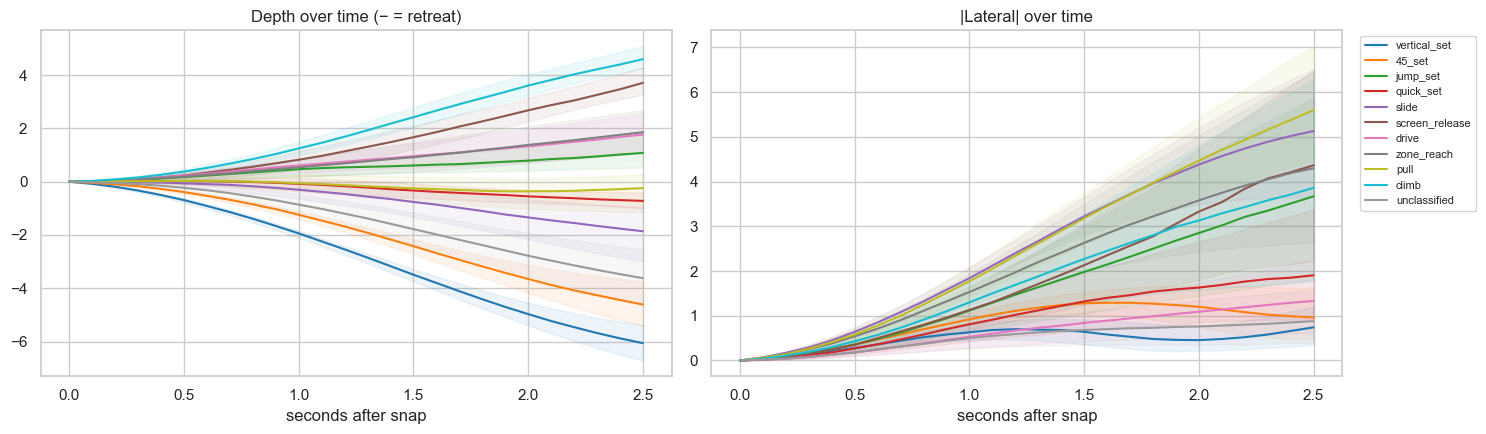

In [8]:
# Depth and lateral over time, by rule class (median and IQR)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
pal = dict(zip(CLASS_ORDER, sns.color_palette("tab10", 10) + [(0.6, 0.6, 0.6)]))
for lab in CLASS_ORDER:
    idx = np.flatnonzero(feat["rule_class"].to_numpy() == lab)
    if len(idx) < 20: continue
    for ax, arr in zip(axes, [DEP, np.abs(LAT)]):
        q = np.percentile(arr[idx], [25, 50, 75], axis=0)
        ax.plot(GRID, q[1], color=pal[lab], label=lab)
        ax.fill_between(GRID, q[0], q[2], color=pal[lab], alpha=.08)
axes[0].set_title("Depth over time (− = retreat)"); axes[1].set_title("|Lateral| over time")
for ax in axes: ax.set_xlabel("seconds after snap")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Unsupervised clustering

**Features:** the full depth and lateral paths on the 0.1 s grid (2 × 26 values), a coarse speed profile, and the timing scalars. Everything is standardized, then PCA reduces it to the components explaining 95% of variance, so the many correlated path points don't dominate.

**Model:** k-means. `MiniBatchKMeans` is used automatically when there are many reps. The k = 10 choice comes from your spec. The k-sweep below shows whether the data itself has a natural number of groups, measured by inertia and silhouette on a sample.

**Pass/run is deliberately left out** of the features, so the clusters are built purely from movement. The cross-tab afterwards shows how cleanly they separate pass from run on their own.

PCA: 6 components explain 95.8%


c:\Users\bchm5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\bchm5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

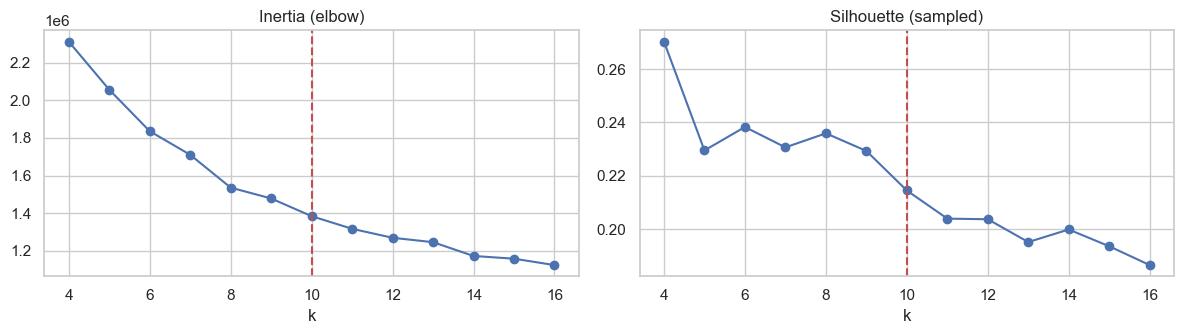

In [9]:
speed_cols = SPD[:, ::5]   # every 0.5 s
scalars = feat[["first_move_s", "peak_speed", "mean_speed", "path_len", "t_min_depth", "t_max_depth"]].fillna(0).to_numpy()
X = np.c_[DEP, LAT, speed_cols, scalars]
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=0.95, random_state=RANDOM).fit(Xs)
Z = pca.transform(Xs)
print(f"PCA: {Z.shape[1]} components explain {pca.explained_variance_ratio_.sum():.1%}")

KM = MiniBatchKMeans if len(Z) > 50_000 else KMeans
sample = np.random.default_rng(RANDOM).choice(len(Z), min(len(Z), 15_000), replace=False)
sweep = []
for k in range(4, 17):
    km = KM(n_clusters=k, random_state=RANDOM, n_init=5).fit(Z)
    sweep.append({"k": k, "inertia": km.inertia_,
                  "silhouette": silhouette_score(Z[sample], km.labels_[sample])})
sweep = pd.DataFrame(sweep)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(sweep["k"], sweep["inertia"], "o-"); axes[0].set_title("Inertia (elbow)")
axes[1].plot(sweep["k"], sweep["silhouette"], "o-"); axes[1].set_title("Silhouette (sampled)")
for ax in axes: ax.axvline(K, color="#C44E52", ls="--"); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

c:\Users\bchm5\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


,reps,pass_share,depth_10,lat_10,max_depth,max_abs_lat,peak_speed,top_rule_class,purity,cluster_name
cluster,,,,,,,,,,
0,5848,0.99,-1.64,-0.45,0.00,1.13,3.27,unclassified,0.58,C0: unclassified
1,18363,0.99,-1.43,0.74,-0.00,1.10,2.97,unclassified,0.52,C1: unclassified
2,15472,0.97,-0.88,0.14,-0.00,0.80,2.47,unclassified,0.98,C2: unclassified
3,13240,0.87,-0.56,0.72,0.00,1.48,2.25,unclassified,0.86,C3: unclassified
4,7024,0.49,-0.31,1.95,0.03,6.43,3.72,slide,0.41,C4: slide (mixed)
5,9219,0.52,-0.11,1.45,0.10,3.52,2.52,unclassified,0.24,C5: unclassified (mixed)
6,11349,0.21,0.33,0.21,0.95,0.93,1.62,drive,0.56,C6: drive
7,5862,0.12,0.59,2.24,2.17,7.58,4.12,zone_reach,0.63,C7: zone_reach
8,11674,0.11,0.69,0.93,1.91,2.07,2.07,drive,0.44,C8: drive (mixed)


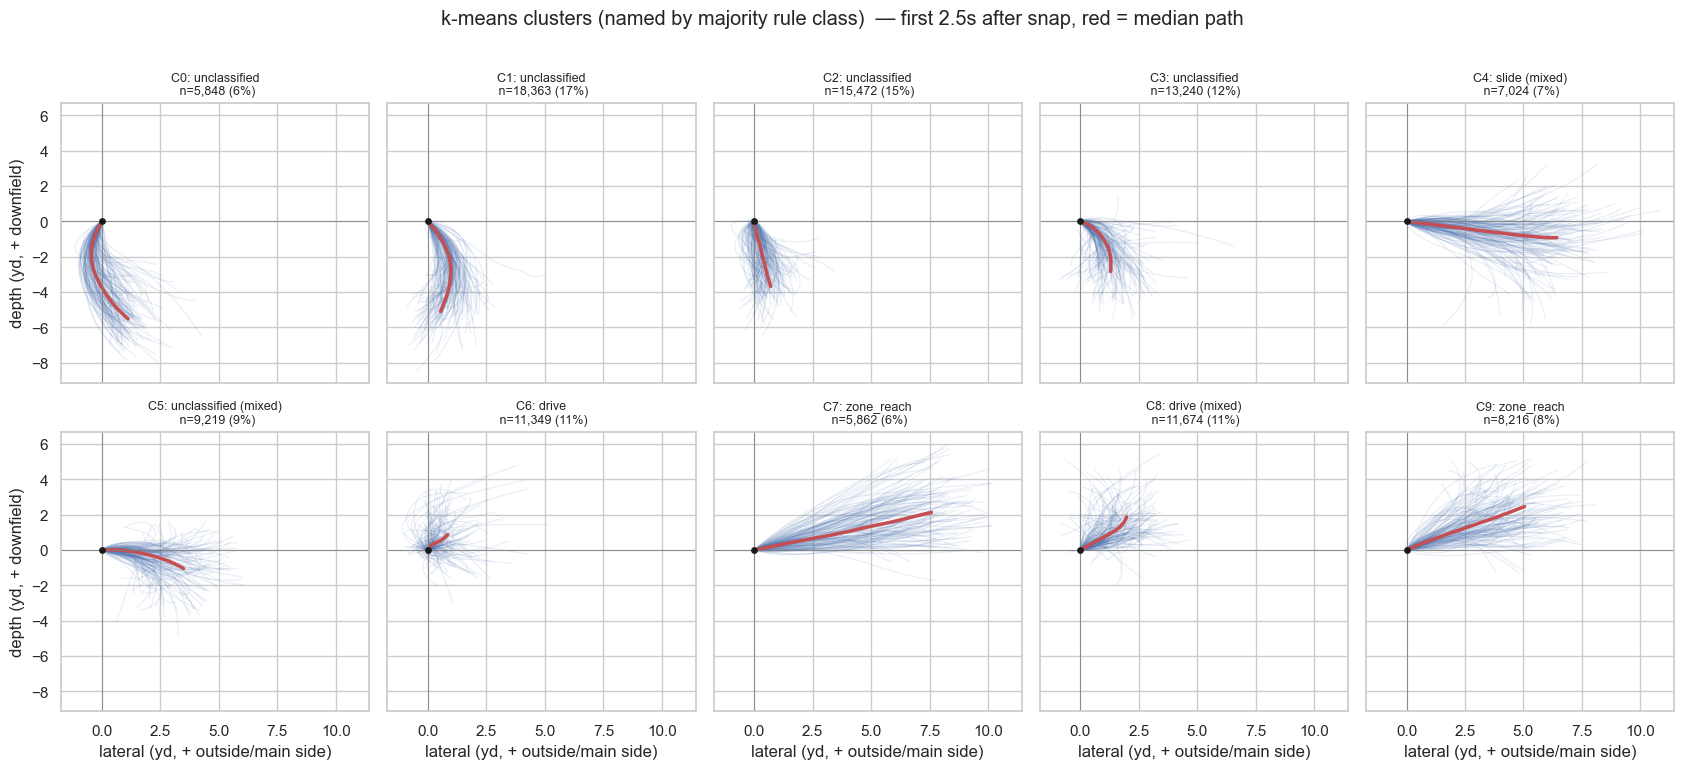

In [10]:
km = KM(n_clusters=K, random_state=RANDOM, n_init=10).fit(Z)
feat["cluster"] = km.labels_

# Order clusters from most retreating to most downfield, so plots read pass → run
order = (feat.groupby("cluster")["depth_10"].median().sort_values().index.tolist())
remap = {c: i for i, c in enumerate(order)}
feat["cluster"] = feat["cluster"].map(remap)

# Suggest a name for each cluster: its most common rule class, and how dominant it is
top = (feat.groupby("cluster")["rule_class"].agg(lambda s: s.value_counts().index[0]).rename("top_rule_class"))
purity = feat.groupby("cluster")["rule_class"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).rename("purity")
desc = (feat.groupby("cluster").agg(reps=("nfl_id", "size"), pass_share=("is_pass", "mean"),
                                   depth_10=("depth_10", "median"), lat_10=("lat_10", "median"),
                                   max_depth=("max_depth", "median"), max_abs_lat=("max_abs_lat", "median"),
                                   peak_speed=("peak_speed", "median"))
          .join(top).join(purity))
desc["cluster_name"] = [f"C{c}: {r.top_rule_class}" + ("" if r.purity >= .5 else " (mixed)") for c, r in desc.iterrows()]
display(desc.round(2))

cl_labels = feat["cluster"].map(desc["cluster_name"]).to_numpy()
spaghetti(cl_labels, desc["cluster_name"].tolist(), "k-means clusters (named by majority rule class)")

## 7. Rules vs. clusters

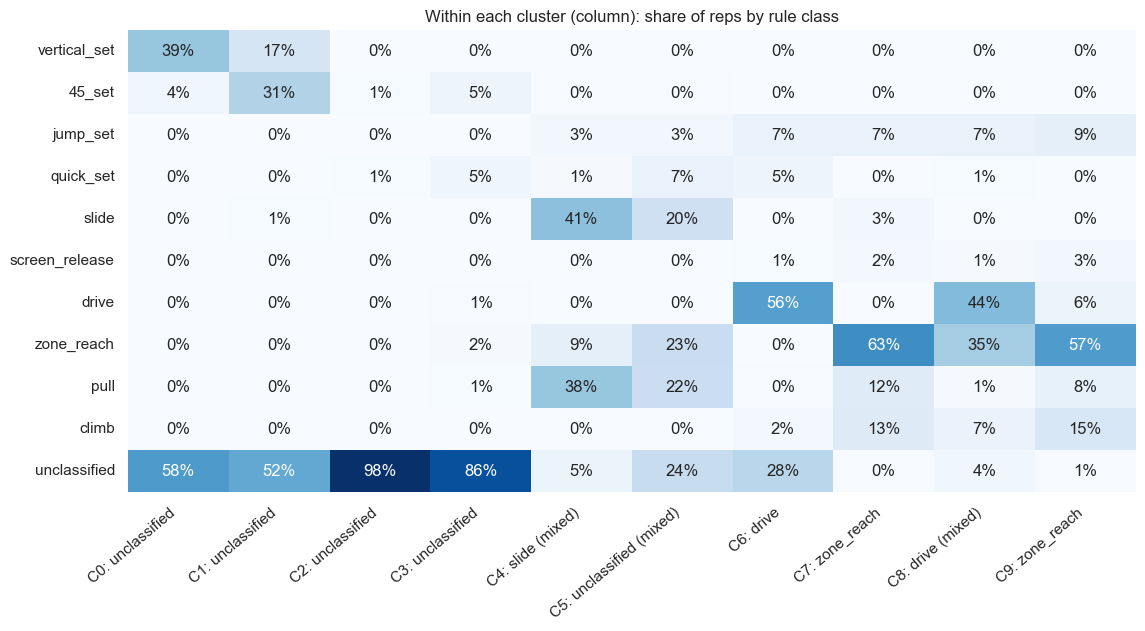

Agreement (excluding unclassified):  ARI = 0.293 | NMI = 0.456


,unclassified reps
cluster,
C2: unclassified,15196
C3: unclassified,11419
C1: unclassified,9475
C0: unclassified,3374
C6: drive,3218
C5: unclassified (mixed),2189
C8: drive (mixed),437
C4: slide (mixed),382
C9: zone_reach,42


In [11]:
ct = pd.crosstab(feat["rule_class"], feat["cluster"].map(desc["cluster_name"]), normalize="columns")
ct = ct.reindex(CLASS_ORDER).dropna(how="all")
plt.figure(figsize=(13, 6))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Within each cluster (column): share of reps by rule class"); plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=40, ha="right"); plt.show()

m = feat["rule_class"] != "unclassified"
print(f"Agreement (excluding unclassified):  ARI = {adjusted_rand_score(feat.loc[m, 'rule_class'], feat.loc[m, 'cluster']):.3f}"
      f" | NMI = {normalized_mutual_info_score(feat.loc[m, 'rule_class'], feat.loc[m, 'cluster']):.3f}")

# Where do unclassified reps land? (tells you which rule thresholds to revisit)
display(feat.loc[~m, "cluster"].map(desc["cluster_name"]).value_counts().to_frame("unclassified reps"))

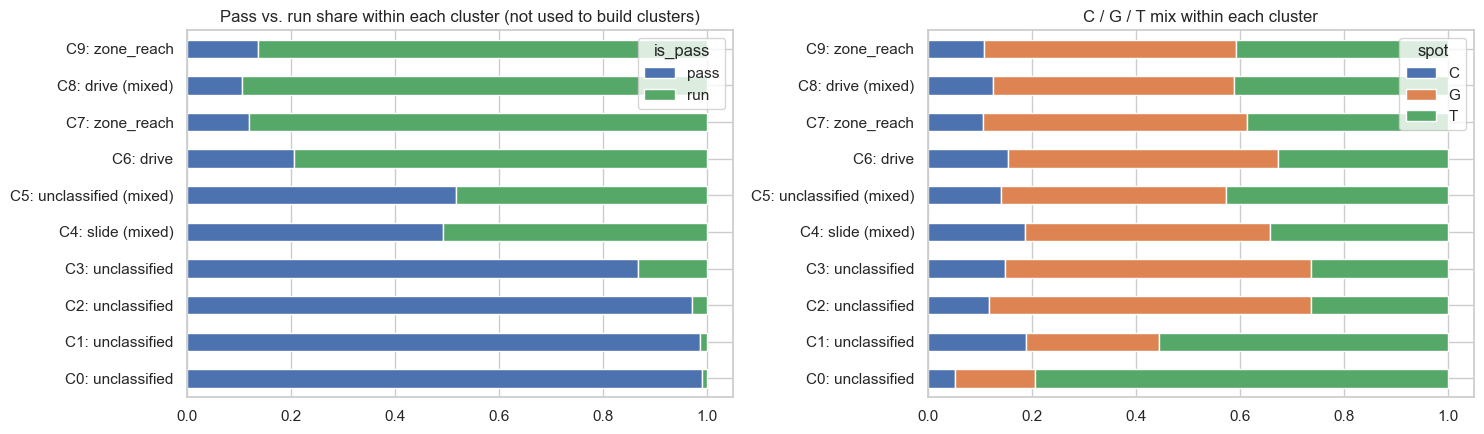

In [12]:
# Pass/run separation and position mix by cluster
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
pr = pd.crosstab(feat["cluster"].map(desc["cluster_name"]), feat["is_pass"].map({1.0: "pass", 0.0: "run"}).fillna("unknown"),
                 normalize="index")
pr.plot.barh(stacked=True, ax=axes[0], color={"pass": "#4C72B0", "run": "#55A868", "unknown": "#BBBBBB"})
axes[0].set_title("Pass vs. run share within each cluster (not used to build clusters)")
sp = pd.crosstab(feat["cluster"].map(desc["cluster_name"]), feat["spot"], normalize="index")
sp.plot.barh(stacked=True, ax=axes[1]); axes[1].set_title("C / G / T mix within each cluster")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 8. Per-player movement profile

Each lineman gets the share of his reps in each class. This is the bridge to the Combine work. For example, you can ask whether players with better mirror-drill movement get used in `vertical_set`/`slide` more, or whether pull-heavy guards share a drill profile. Players with few reps are noisy, so a `reps` column is kept for filtering.

In [13]:
prof_rule = pd.crosstab(feat["nfl_id"], feat["rule_class"], normalize="index").reindex(columns=CLASS_ORDER, fill_value=0)
prof_rule.columns = [f"rule_{c}" for c in prof_rule.columns]
prof_cl = pd.crosstab(feat["nfl_id"], feat["cluster"], normalize="index")
prof_cl.columns = [f"cluster_{c}" for c in prof_cl.columns]
player_profile = (feat.groupby("nfl_id").agg(reps=("play_id", "size"), primary_spot=("spot", lambda s: s.mode().iloc[0]))
                      .join(prof_rule).join(prof_cl))
if "players" in globals():
    nm = pick(players, ["display_name", "player_name", "full_name", "name"])
    if nm: player_profile = player_profile.join(players.set_index("nfl_id")[[nm]], how="left")
display(player_profile.sort_values("reps", ascending=False).head(15).round(2))

feat.to_csv("ol_rep_movement_classes.csv", index=False)
player_profile.to_csv("ol_player_movement_profile.csv")
print("Saved ol_rep_movement_classes.csv (one row per rep) and ol_player_movement_profile.csv (one row per player)")

,reps,primary_spot,rule_vertical_set,rule_45_set,rule_jump_set,rule_quick_set,rule_slide,rule_screen_release,rule_drive,rule_zone_reach,...,cluster_0,cluster_1,cluster_2,cluster_3,cluster_4,cluster_5,cluster_6,cluster_7,cluster_8,cluster_9
nfl_id,,,,,,,,,,,,,,,,,,,,,
55924,3921,G,0.00,0.07,0.04,0.02,0.04,0.01,0.16,0.13,...,0.02,0.13,0.17,0.14,0.05,0.08,0.18,0.04,0.11,0.08
55874,3461,T,0.11,0.04,0.04,0.03,0.05,0.00,0.10,0.15,...,0.07,0.23,0.13,0.07,0.06,0.08,0.09,0.06,0.12,0.09
55891,3170,T,0.09,0.07,0.02,0.02,0.05,0.01,0.12,0.12,...,0.11,0.24,0.11,0.09,0.05,0.08,0.10,0.04,0.12,0.06
55903,3165,G,0.01,0.09,0.03,0.01,0.07,0.01,0.07,0.22,...,0.02,0.15,0.13,0.11,0.11,0.08,0.06,0.17,0.09,0.07
55875,3156,G,0.01,0.05,0.03,0.02,0.06,0.01,0.13,0.12,...,0.03,0.10,0.21,0.15,0.10,0.08,0.11,0.05,0.10,0.08
55901,3009,G,0.00,0.06,0.03,0.02,0.05,0.01,0.18,0.10,...,0.02,0.08,0.20,0.18,0.06,0.08,0.17,0.04,0.12,0.06
55870,2842,T,0.14,0.10,0.02,0.01,0.03,0.00,0.09,0.15,...,0.14,0.31,0.06,0.07,0.05,0.07,0.08,0.05,0.11,0.07
55878,2841,T,0.09,0.08,0.02,0.02,0.04,0.00,0.09,0.16,...,0.05,0.26,0.11,0.10,0.07,0.10,0.09,0.03,0.10,0.09
55913,2688,G,0.01,0.05,0.03,0.02,0.04,0.01,0.13,0.13,...,0.03,0.12,0.23,0.13,0.05,0.09,0.13,0.03,0.11,0.09


Saved ol_rep_movement_classes.csv (one row per rep) and ol_player_movement_profile.csv (one row per player)


## Notes for tuning

- **Start with the unclassified table in Section 7.** If most unclassified reps land in one cluster, that cluster's spaghetti plot shows which threshold is too strict.
- **Validate on film-like spot checks.** Pull a few reps per rule class and plot them with `plot_play` from the viewer notebook. If a `pull` looks like a long reach, raise `pull_lat`.
- **Without a ball or QB, some classes are blurry.** Quick set vs. jump set, and drive vs. down block, depend on context that isn't tracked. Expect the clusters to merge those, which is a finding in itself.
- **`WINDOW_S` changes everything downstream.** 2.5 s captures most sets and pulls. Shorten it to focus on the first few steps, which is likely closest to what the Combine drills measure.